# 🙂 Emotion-aware Cognitive Assistant
**Face detection (OpenCV) + LandingLens emotion classification + reasoning + Text-to-Speech**

**Pipeline**
1. **Perceive:** take an image file or a webcam snapshot
2. **Detect:** OpenCV finds each face in the image
3. **Recognise:** the LandingLens classification model (trained on JAFFE) predicts the emotion of each face
4. **Reason:** the assistant combines the emotion, its confidence and the recent mood history to choose a response
5. **Respond:** it shows an annotated image and report, and **speaks** an empathetic reply

**Before running:** add your emotion model's endpoint to `a.env` as `LANDINGAI_EMOTION_ENDPOINT_ID=...` (the API key line stays the same).

In [ ]:
%pip install -q landingai "opencv-python<5" pillow matplotlib gTTS python-dotenv

In [1]:
import getpass
import os
from collections import Counter, deque
from datetime import datetime

import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw
from IPython.display import display, Markdown, Audio
from gtts import gTTS
from dotenv import load_dotenv
from landingai.predict import Predictor

## 1. Configuration

In [16]:
load_dotenv("a.env")

API_KEY = os.environ.get("LANDINGAI_API_KEY")
ENDPOINT_ID = "d7035a75-131f-4750-8b1f-a705884b8c39"

MIN_CONFIDENCE = 0.50        # below this, the assistant says it is unsure
MATCH_TRAINING_STYLE = True  # convert face crops to grayscale like the training images
FACE_SIZE = 128              # must match the size used in prepare_jaffe.py
NEGATIVE_EMOTIONS = {"sad", "angry", "fear", "disgust"}

predictor = Predictor(endpoint_id=ENDPOINT_ID, api_key=API_KEY)
# Haar cascade face detector (OpenCV 4.x). If unavailable, the whole image is treated as one face.
if hasattr(cv2, "CascadeClassifier"):
    face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
else:
    face_cascade = None
    print("OpenCV face detector not available; install opencv-python<5.")

mood_history = deque(maxlen=20)   # the assistant's short-term memory
print("Emotion assistant ready.")

Emotion assistant ready.


## 2. Perception: load an image or take a webcam snapshot

In [6]:
def load_image(image_path):
    with Image.open(image_path) as img:
        return img.convert("RGB").copy()


def capture_webcam(camera_index=0):
    cam = cv2.VideoCapture(camera_index)
    for _ in range(5):                 # let the camera adjust exposure
        ok, frame = cam.read()
    cam.release()
    if not ok:
        raise RuntimeError("Could not read from the webcam.")
    return Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

## 3. Face detection (OpenCV)

In [7]:
def detect_faces(image):
    """Returns a list of (x, y, w, h) boxes, largest face first."""
    if face_cascade is None:
        return []
    gray = cv2.cvtColor(np.array(image), cv2.COLOR_RGB2GRAY)
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(48, 48))
    boxes = [tuple(int(v) for v in f) for f in faces]
    return sorted(boxes, key=lambda b: b[2] * b[3], reverse=True)


def prepare_face(image, box, margin=0.10):
    x, y, w, h = box
    mx, my = int(w * margin), int(h * margin)
    crop = image.crop((max(0, x - mx), max(0, y - my),
                       min(image.width, x + w + mx), min(image.height, y + h + my)))
    if MATCH_TRAINING_STYLE:
        crop = crop.convert("L").resize((FACE_SIZE, FACE_SIZE)).convert("RGB")
    return crop

## 4. Emotion recognition (LandingLens classification)

In [8]:
LABEL_ALIASES = {
    "happiness": "happy", "joy": "happy",
    "sadness": "sad",
    "anger": "angry",
    "fearful": "fear", "scared": "fear",
    "surprised": "surprise",
    "disgusted": "disgust",
    "calm": "neutral",
}


def classify_emotion(face_img):
    predictions = predictor.predict(np.array(face_img))
    if not predictions:
        return None, 0.0
    best = max(predictions, key=lambda p: p.score)   # ClassificationPrediction
    label = best.label_name.strip().lower()
    return LABEL_ALIASES.get(label, label), float(best.score)

## 5. Cognitive reasoning: choose a response using emotion, confidence and memory

In [9]:
RESPONSES = {
    "happy":    ("You look happy! It's great to see that.",
                 "This is a good moment to take on something challenging."),
    "sad":      ("You seem a little sad.",
                 "Maybe take a short break, listen to some music, or talk to someone you trust."),
    "angry":    ("You seem frustrated.",
                 "Try a few slow, deep breaths before you continue."),
    "fear":     ("You look worried.",
                 "It's okay. Try breaking the task into smaller steps."),
    "surprise": ("You look surprised!",
                 "Did something unexpected happen?"),
    "disgust":  ("Something seems to be bothering you.",
                 "Would it help to step away from it for a moment?"),
    "neutral":  ("You look calm and focused.",
                 "Carry on. I'm here if you need anything."),
}


def decide_response(emotion, confidence):
    """Returns (message, suggestion, reasoning_note)."""
    if emotion is None or confidence < MIN_CONFIDENCE:
        return ("I'm not sure how you're feeling.",
                "Could you face the camera in better light?",
                f"Confidence {confidence:.2f} is below {MIN_CONFIDENCE}")

    message, suggestion = RESPONSES.get(emotion, (f"You seem {emotion}.", ""))
    recent = [e for _, e, c in list(mood_history)[-3:] if c >= MIN_CONFIDENCE]
    previous = recent[-1] if recent else None

    # Memory rule 1: the same negative emotion keeps appearing
    if emotion in NEGATIVE_EMOTIONS and len(recent) >= 2 and all(e in NEGATIVE_EMOTIONS for e in recent[-2:]):
        suggestion = ("You've seemed upset for a while now. Please take a proper break, "
                      "and consider talking to a friend or someone you trust.")
        note = "Negative emotion detected 3 times in a row: escalated suggestion"
    # Memory rule 2: mood improved
    elif emotion in {"happy", "neutral"} and previous in NEGATIVE_EMOTIONS:
        message = "You look better than before. I'm glad!"
        note = f"Mood improved from {previous} to {emotion}"
    else:
        note = "Response based on current emotion"
    return message, suggestion, note

## 6. The emotion-aware assistant

In [10]:
EMOJI = {"happy": "😀", "sad": "😢", "angry": "😠", "fear": "😨",
         "surprise": "😮", "disgust": "🤢", "neutral": "😐"}


def emotion_assistant(image_path=None, use_webcam=False, save=True):
    print("Emotion-aware Cognitive Assistant")

    # 1. Perceive
    if use_webcam:
        image = capture_webcam()
        base = "webcam_" + datetime.now().strftime("%H%M%S")
    else:
        if not image_path or not os.path.exists(image_path):
            print("File not found:", image_path)
            return
        image = load_image(image_path)
        base = os.path.splitext(os.path.basename(image_path))[0]

    # 2. Detect faces (if none, assume the image is already a face crop)
    boxes = detect_faces(image)
    if not boxes:
        print("No face detected by OpenCV; treating the whole image as one face.")
        boxes = [(0, 0, image.width, image.height)]

    # 3. Recognise each face's emotion
    results = []
    annotated = image.copy()
    draw = ImageDraw.Draw(annotated)
    for i, box in enumerate(boxes, start=1):
        emotion, conf = classify_emotion(prepare_face(image, box))
        results.append((i, box, emotion, conf))
        x, y, w, h = box
        colour = "red" if emotion in NEGATIVE_EMOTIONS else "lime"
        draw.rectangle([x, y, x + w, y + h], outline=colour, width=3)
        draw.text((x + 4, max(0, y - 14)), f"{i}: {emotion} {conf:.2f}", fill=colour)
    display(annotated)

    # 4. Reason about the main (largest) face, using memory
    _, _, emotion, conf = results[0]
    message, suggestion, note = decide_response(emotion, conf)
    mood_history.append((datetime.now(), emotion, conf))

    # 5. Report
    rows = "\n".join(f"| {i} | {EMOJI.get(e, '')} {e or '—'} | {c:.2f} |" for i, _, e, c in results)
    report = f"""
### Assistant response: {EMOJI.get(emotion, '❓')} **{(emotion or 'unknown').upper()}**

| Face | Emotion | Confidence |
|---|---|---|
{rows}

**Assistant says:** {message} {suggestion}

*Reasoning:* {note}
"""
    if len(results) > 1:
        group = Counter(e for _, _, e, _ in results)
        report += "\n*Group mood:* " + ", ".join(f"{k}: {v}" for k, v in group.items())
    display(Markdown(report))

    # 6. Speak
    speech_text = f"{message} {suggestion}"
    if len(results) > 1:
        speech_text = f"I can see {len(results)} people. " + speech_text
    print("Spoken response:", speech_text)
    gTTS(text=speech_text, lang="en").save(f"{base}_response.mp3")
    display(Audio(f"{base}_response.mp3", autoplay=False))

    # 7. Save outputs for the report
    if save:
        annotated.save(f"{base}_detected.jpg")
        with open(f"{base}_report.md", "w", encoding="utf-8") as f:
            f.write(report + "\n\n**Spoken response:** " + speech_text + "\n")
        print(f"Saved: {base}_detected.jpg, {base}_report.md, {base}_response.mp3")

## 7. Mood summary (the assistant's memory over the session)

In [11]:
def mood_summary():
    if not mood_history:
        print("No emotions recorded yet.")
        return
    counts = Counter(e for _, e, _ in mood_history)
    plt.figure(figsize=(6, 3))
    plt.bar(list(counts.keys()), list(counts.values()))
    plt.title("Emotions detected this session")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.savefig("mood_summary.png")
    plt.show()
    print("Timeline:", " → ".join(e or "unknown" for _, e, _ in mood_history))

## 8. Run the assistant
Use an image file, or set `use_webcam=True` to take a snapshot.

Emotion-aware Cognitive Assistant


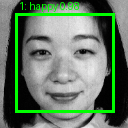


### Assistant response: 😀 **HAPPY**

| Face | Emotion | Confidence |
|---|---|---|
| 1 | 😀 happy | 0.98 |

**Assistant says:** You look happy! It's great to see that. This is a good moment to take on something challenging.

*Reasoning:* Response based on current emotion


Spoken response: You look happy! It's great to see that. This is a good moment to take on something challenging.


Saved: YM.HA1.52_detected.jpg, YM.HA1.52_report.md, YM.HA1.52_response.mp3


In [13]:
emotion_assistant(r"C:\Users\Aman\cognitive\emotion\jaffe_sorted\test\happy\YM.HA1.52.png")

Emotion-aware Cognitive Assistant


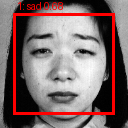


### Assistant response: 😢 **SAD**

| Face | Emotion | Confidence |
|---|---|---|
| 1 | 😢 sad | 0.68 |

**Assistant says:** You seem a little sad. Maybe take a short break, listen to some music, or talk to someone you trust.

*Reasoning:* Response based on current emotion


Spoken response: You seem a little sad. Maybe take a short break, listen to some music, or talk to someone you trust.


Saved: YM.SA1.55_detected.jpg, YM.SA1.55_report.md, YM.SA1.55_response.mp3


In [17]:
emotion_assistant(r"C:\Users\Aman\cognitive\emotion\jaffe_sorted\test\sad\YM.SA1.55.png")

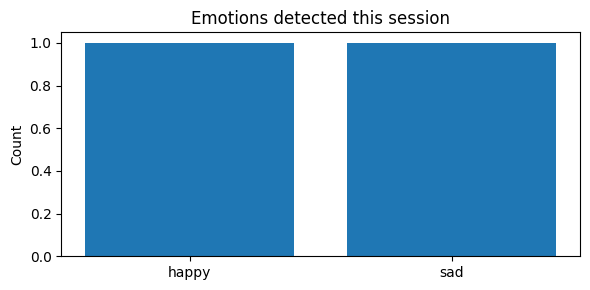

Timeline: happy → sad


In [15]:
mood_summary()